# MultiUsvEnv 全面测试

本 Notebook 用于对 `MultiUsvEnv` 进行结构化、可复现的全面测试。

覆盖内容：
1. Seed 复现性
2. 观测/动作接口一致性
3. Active Mask 冻结机制
4. 输入参数校验
5. 全局目标状态同步
6. USV-USV 碰撞检测
7. USV-障碍物碰撞检测
8. 超步数终止条件
9. all_sequence_completed 终止条件
10. 随机短程压力测试

In [1]:
import os
import sys
import traceback
import numpy as np

# 将项目根目录加入导入路径（当前 notebook 位于 test/ 下）
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.insert(0, project_root)

from my_USV_Env import MultiUsvEnv

print('导入成功:', MultiUsvEnv)

导入成功: <class 'my_USV_Env.MultiUsvEnv'>


In [2]:
# 测试工具函数
def assert_true(cond, msg):
    if not cond:
        raise AssertionError(msg)

def assert_allclose(a, b, msg, atol=1e-6):
    if not np.allclose(a, b, atol=atol):
        raise AssertionError(msg)

def allclose_nested_obs(obs_a, obs_b, atol=1e-6):
    if set(obs_a.keys()) != set(obs_b.keys()):
        return False
    for k in obs_a.keys():
        if set(obs_a[k].keys()) != set(obs_b[k].keys()):
            return False
        for sub_k in obs_a[k].keys():
            if not np.allclose(obs_a[k][sub_k], obs_b[k][sub_k], atol=atol):
                return False
    return True

print('测试工具加载完成')

测试工具加载完成


In [4]:
# 1) Seed 复现性
def test_seed_reproducibility():
    env_a = MultiUsvEnv(num_usvs=2, num_targets=6, num_obstacles=5, seed=2026, current_type='generated')
    obs_a = env_a.reset(seed=2026)
    starts_a = np.array(env_a.start_positions, dtype=np.float32)
    targets_a = np.array([[t.x, t.y] for t in env_a.targets], dtype=np.float32)

    env_b = MultiUsvEnv(num_usvs=2, num_targets=6, num_obstacles=5, seed=2026, current_type='generated')
    obs_b = env_b.reset(seed=2026)
    starts_b = np.array(env_b.start_positions, dtype=np.float32)
    targets_b = np.array([[t.x, t.y] for t in env_b.targets], dtype=np.float32)

    assert_allclose(starts_a, starts_b, '相同 seed 下起点不一致')
    assert_allclose(targets_a, targets_b, '相同 seed 下目标不一致')
    assert_true(allclose_nested_obs(obs_a, obs_b), '相同 seed 下初始观测不一致')


# 2) 观测/动作接口一致性
def test_observation_action_interfaces():
    env = MultiUsvEnv(num_usvs=2, num_targets=4, num_obstacles=3, seed=101, current_type='generated')
    obs = env.reset(seed=101)

    assert_true(set(obs.keys()) == {'usv_0', 'usv_1'}, '多USV观测主键不正确')
    for usv_k in ['usv_0', 'usv_1']:
        for sub_k in ['o_usv', 'targets', 'o_current', 'o_detector']:
            assert_true(sub_k in obs[usv_k], f'{usv_k} 缺少字段 {sub_k}')
            arr = obs[usv_k][sub_k]
            assert_true(np.all(np.isfinite(arr)), f'{usv_k}.{sub_k} 存在非有限值')

    actions = np.zeros((2, 2), dtype=np.float32)
    goals = [
        np.array([env.targets[0].x, env.targets[0].y], dtype=np.float32),
        np.array([env.targets[1].x, env.targets[1].y], dtype=np.float32),
    ]
    obs2, done2, crush2, truncated2, info2 = env.step(actions, goals)

    assert_true(isinstance(done2, (bool, np.bool_)), 'done 类型异常')
    assert_true(isinstance(crush2, (bool, np.bool_)), 'crush 类型异常')
    assert_true(isinstance(truncated2, (bool, np.bool_)), 'truncated 类型异常')
    assert_true('termination_reason' in info2, 'info 缺少 termination_reason')
    assert_true(obs2['usv_0']['o_usv'].shape[0] == 7, 'o_usv 维度应为 7')


# 3) Active Mask 冻结
def test_active_mask_freeze():
    env = MultiUsvEnv(num_usvs=2, num_targets=4, num_obstacles=3, seed=111, current_type='generated')
    _ = env.reset(seed=111)

    pre = np.array([[u.x, u.y] for u in env.usvs], dtype=np.float32)
    actions = np.array([[0.8, 0.0], [0.8, 0.0]], dtype=np.float32)
    goals = [
        np.array([env.targets[0].x, env.targets[0].y], dtype=np.float32),
        np.array([env.targets[1].x, env.targets[1].y], dtype=np.float32),
    ]
    mask = np.array([True, False], dtype=bool)

    _, _, _, _, _ = env.step(actions, goals, usv_active_mask=mask)
    post = np.array([[u.x, u.y] for u in env.usvs], dtype=np.float32)

    assert_true(not np.allclose(pre[0], post[0]), 'active=True 的 USV 位置未更新')
    assert_true(np.allclose(pre[1], post[1]), 'active=False 的 USV 位置发生变化')


# 4) 输入参数校验
def test_input_validation_errors():
    env = MultiUsvEnv(num_usvs=2, num_targets=3, num_obstacles=2, seed=12, current_type='generated')
    _ = env.reset(seed=12)

    goals = [
        np.array([env.targets[0].x, env.targets[0].y], dtype=np.float32),
        np.array([env.targets[1].x, env.targets[1].y], dtype=np.float32),
    ]

    bad_action_raised = False
    try:
        env.step(np.zeros((2, 3), dtype=np.float32), goals)
    except ValueError:
        bad_action_raised = True
    assert_true(bad_action_raised, '错误动作维度未触发 ValueError')

    bad_goal_raised = False
    try:
        env.step(np.zeros((2, 2), dtype=np.float32), goals[:1])
    except ValueError:
        bad_goal_raised = True
    assert_true(bad_goal_raised, '错误 goals 长度未触发 ValueError')


# 5) 全局目标状态同步
def test_global_target_status_sync():
    env = MultiUsvEnv(
        num_usvs=2,
        num_targets=2,
        num_obstacles=0,
        seed=7,
        current_type='generated',
        fixed_start_positions=[np.array([10.0, 10.0]), np.array([90.0, 90.0])],
        fixed_targets=[np.array([30.0, 30.0]), np.array([70.0, 70.0])]
    )
    _ = env.reset(seed=7)

    env.usvs[0].x, env.usvs[0].y = 30.0, 30.0
    env.usvs[1].x, env.usvs[1].y = 70.0, 70.0
    env.usvs[0]._update_polygon()
    env.usvs[1]._update_polygon()
    env.current_positions = np.array([[30.0, 30.0], [70.0, 70.0]], dtype=np.float32)

    actions = np.zeros((2, 2), dtype=np.float32)
    goals = [np.array([30.0, 30.0], dtype=np.float32), np.array([70.0, 70.0], dtype=np.float32)]
    _, _, _, _, info = env.step(actions, goals, usv_active_mask=np.array([False, False], dtype=bool))

    assert_true(int(info['target_status'].sum()) == 2, '目标全局状态未正确更新')


# 6) USV-USV 碰撞检测
def test_usv_usv_collision_detection():
    env = MultiUsvEnv(
        num_usvs=2,
        num_targets=2,
        num_obstacles=0,
        seed=77,
        current_type='generated',
        fixed_start_positions=[np.array([20.0, 20.0]), np.array([80.0, 80.0])]
    )
    _ = env.reset(seed=77)

    env.usvs[0].x, env.usvs[0].y = 50.0, 50.0
    env.usvs[1].x, env.usvs[1].y = 50.0, 50.0
    env.usvs[0]._update_polygon()
    env.usvs[1]._update_polygon()
    env.current_positions = np.array([[50.0, 50.0], [50.0, 50.0]], dtype=np.float32)

    actions = np.zeros((2, 2), dtype=np.float32)
    goals = [np.array([60.0, 60.0], dtype=np.float32), np.array([40.0, 40.0], dtype=np.float32)]
    _, done, crush, _, info = env.step(actions, goals, usv_active_mask=np.array([False, False], dtype=bool))

    assert_true(crush, '重叠构造下 crush 应为 True')
    assert_true(len(info['usv_collision_pairs']) > 0, '应检测到 usv_collision_pairs')
    assert_true(done, '碰撞时 done 应为 True')


# 7) USV-障碍物碰撞检测
def test_usv_obstacle_collision_detection():
    env = MultiUsvEnv(
        num_usvs=2,
        num_targets=2,
        num_obstacles=1,
        seed=41,
        current_type='generated',
        fixed_obstacles=[np.array([50.0, 50.0, 8.0])],
        fixed_start_positions=[np.array([10.0, 10.0]), np.array([90.0, 90.0])]
    )
    _ = env.reset(seed=41)

    env.usvs[0].x, env.usvs[0].y = 50.0, 50.0
    env.usvs[0]._update_polygon()
    env.current_positions[0] = np.array([50.0, 50.0], dtype=np.float32)

    actions = np.zeros((2, 2), dtype=np.float32)
    goals = [np.array([80.0, 80.0], dtype=np.float32), np.array([20.0, 20.0], dtype=np.float32)]
    _, done, crush, _, info = env.step(actions, goals, usv_active_mask=np.array([False, False], dtype=bool))

    assert_true(crush, '障碍物重叠下 crush 应为 True')
    assert_true(any(info['obstacle_collisions']), '应检测到 obstacle_collisions')
    assert_true(done, '碰撞时 done 应为 True')


# 8) 超步数终止
def test_all_active_timeout_termination():
    env = MultiUsvEnv(
        num_usvs=2,
        num_targets=2,
        num_obstacles=0,
        seed=88,
        per_usv_max_steps=2,
        current_type='generated',
        fixed_start_positions=[np.array([10.0, 10.0]), np.array([90.0, 90.0])]
    )
    _ = env.reset(seed=88)

    actions = np.zeros((2, 2), dtype=np.float32)
    goals = [np.array([95.0, 95.0], dtype=np.float32), np.array([5.0, 5.0], dtype=np.float32)]

    out = None
    for _ in range(3):
        out = env.step(actions, goals, usv_active_mask=np.array([True, True], dtype=bool))

    _, done, crush, truncated, info = out
    assert_true(done, '超步数后 done 应为 True')
    assert_true(truncated, '超步数后 truncated 应为 True')
    assert_true(not crush, '该构造场景不应碰撞')
    assert_true(info['termination_reason'] == 'all_active_timeout', '终止原因应为 all_active_timeout')


# 9) all_sequence_completed 终止
def test_all_sequence_completed_termination():
    env = MultiUsvEnv(num_usvs=2, num_targets=2, num_obstacles=0, seed=66, current_type='generated')
    _ = env.reset(seed=66)

    actions = np.zeros((2, 2), dtype=np.float32)
    goals = [
        np.array([env.targets[0].x, env.targets[0].y], dtype=np.float32),
        np.array([env.targets[1].x, env.targets[1].y], dtype=np.float32),
    ]
    _, done, crush, truncated, info = env.step(actions, goals, usv_active_mask=np.array([False, False], dtype=bool))

    assert_true(done, 'all_sequence_completed 下 done 应为 True')
    assert_true(not crush, 'all_sequence_completed 构造不应碰撞')
    assert_true(not truncated, 'all_sequence_completed 下 truncated 应为 False')
    assert_true(info['termination_reason'] == 'all_sequence_completed', '终止原因应为 all_sequence_completed')


# 10) 短程随机压力测试
def test_short_random_stress():
    env = MultiUsvEnv(num_usvs=2, num_targets=4, num_obstacles=4, seed=303, current_type='generated')
    obs = env.reset(seed=303)

    for step_i in range(80):
        actions = env.action_space.sample().astype(np.float32)
        goals = []
        for i in range(env.num_usvs):
            target_i = env.targets[i % env.num_targets]
            goals.append(np.array([target_i.x, target_i.y], dtype=np.float32))

        obs, done, crush, truncated, info = env.step(actions, goals, usv_active_mask=np.array([True, True], dtype=bool))

        assert_true(set(obs.keys()) == {'usv_0', 'usv_1'}, '压力测试中观测主键异常')
        for usv_k in ['usv_0', 'usv_1']:
            for sub_k in ['o_usv', 'targets', 'o_current', 'o_detector']:
                arr = obs[usv_k][sub_k]
                assert_true(np.all(np.isfinite(arr)), f'压力测试第{step_i}步 {usv_k}.{sub_k} 出现非有限值')

        if done:
            assert_true(info['termination_reason'] in ['collision', 'all_sequence_completed', 'all_active_timeout'], '未知终止原因')
            break


print('测试函数定义完成')

测试函数定义完成


In [5]:
# 运行全部测试并输出汇总
test_cases = [
    ('Seed 复现性', test_seed_reproducibility),
    ('观测/动作接口一致性', test_observation_action_interfaces),
    ('Active Mask 冻结', test_active_mask_freeze),
    ('输入参数校验', test_input_validation_errors),
    ('全局目标状态同步', test_global_target_status_sync),
    ('USV-USV 碰撞检测', test_usv_usv_collision_detection),
    ('USV-障碍物碰撞检测', test_usv_obstacle_collision_detection),
    ('超步数终止条件', test_all_active_timeout_termination),
    ('all_sequence_completed 终止条件', test_all_sequence_completed_termination),
    ('短程随机压力测试', test_short_random_stress),
]

results = []
for name, fn in test_cases:
    try:
        fn()
        print(f'[PASS] {name}')
        results.append((name, 'PASS', ''))
    except Exception as e:
        print(f'[FAIL] {name}: {e}')
        traceback.print_exc(limit=1)
        results.append((name, 'FAIL', str(e)))

pass_count = sum(1 for _, status, _ in results if status == 'PASS')
fail_count = len(results) - pass_count

print('\n' + '=' * 72)
print(f'测试总数: {len(results)} | 通过: {pass_count} | 失败: {fail_count}')
print('=' * 72)

if fail_count > 0:
    print('失败项:')
    for name, status, msg in results:
        if status == 'FAIL':
            print(f'  - {name}: {msg}')
else:
    print('所有 MultiUsvEnv 测试均通过。')

d:\Anaconda\anaconda3\envs\RL\lib\site-packages\gymnasium\spaces\box.py:130: UserWarning: WARN: Box bound precision lowered by casting to float32
  gym.logger.warn(f"Box bound precision lowered by casting to {self.dtype}")


[PASS] Seed 复现性
[PASS] 观测/动作接口一致性
[PASS] Active Mask 冻结
[PASS] 输入参数校验
[PASS] 全局目标状态同步
[PASS] USV-USV 碰撞检测
[PASS] USV-障碍物碰撞检测
[PASS] 超步数终止条件
[PASS] all_sequence_completed 终止条件
[PASS] 短程随机压力测试

测试总数: 10 | 通过: 10 | 失败: 0
所有 MultiUsvEnv 测试均通过。


## 11. 多USV环境可视化

本节绘制多USV初始环境：
- 障碍物（不同形状）
- 目标点与目标半径
- 多艘USV起点与朝向

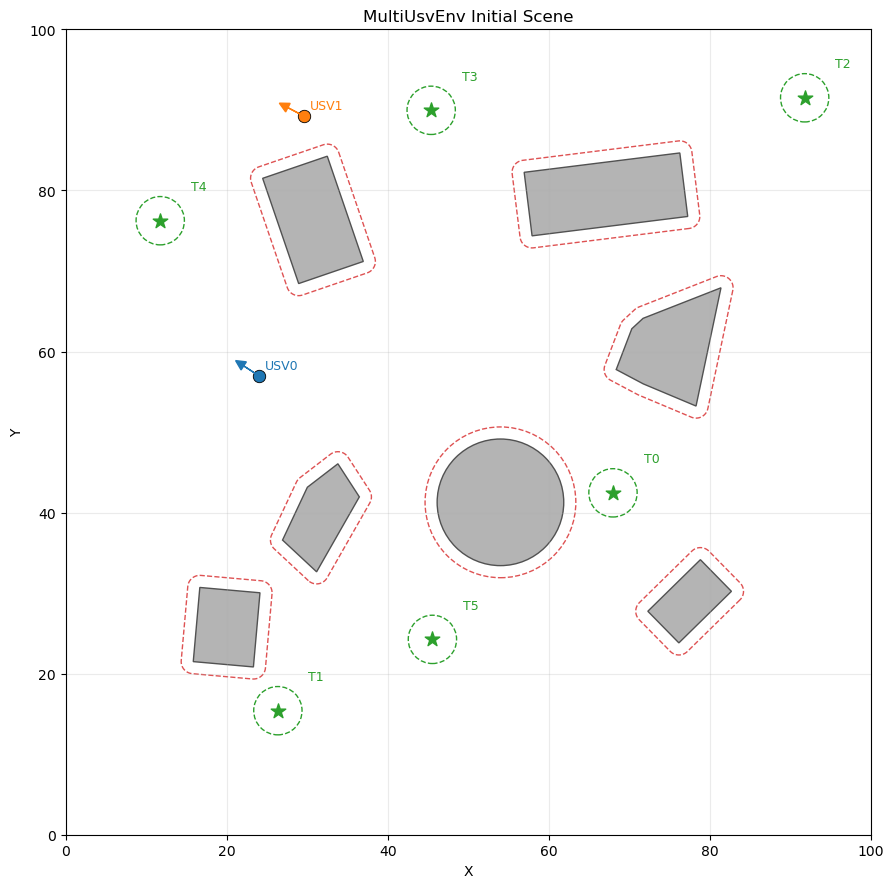

In [6]:
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Polygon as MplPolygon


def plot_multi_usv_env(env, ax=None, title='MultiUsvEnv Scene'):
    if ax is None:
        fig, ax = plt.subplots(figsize=(9, 9))

    # 障碍物
    for obs in env.obstacles:
        shape = getattr(obs.shape, 'value', str(obs.shape))
        if shape == 'circle':
            ax.add_patch(Circle((obs.x, obs.y), obs.radius_o, facecolor='#B0B0B0', edgecolor='#4A4A4A', linewidth=1.0, alpha=0.95))
            ax.add_patch(Circle((obs.x, obs.y), obs.radius_o + obs.rou_c, facecolor='none', edgecolor='#D62728', linestyle='--', linewidth=1.0, alpha=0.8))
        else:
            verts = np.array(list(obs.geometry.exterior.coords)[:-1], dtype=np.float32)
            ax.add_patch(MplPolygon(verts, closed=True, facecolor='#B0B0B0', edgecolor='#4A4A4A', linewidth=1.0, alpha=0.95))
            danger_verts = np.array(list(obs.danger_zone.exterior.coords)[:-1], dtype=np.float32)
            ax.add_patch(MplPolygon(danger_verts, closed=True, facecolor='none', edgecolor='#D62728', linestyle='--', linewidth=1.0, alpha=0.8))

    # 目标
    for i, t in enumerate(env.targets):
        ax.add_patch(Circle((t.x, t.y), t.radius_t, facecolor='none', edgecolor='#2CA02C', linestyle='--', linewidth=1.0))
        ax.scatter(t.x, t.y, marker='*', s=120, c='#2CA02C', zorder=5)
        ax.text(t.x + t.radius_t + 0.8, t.y + t.radius_t + 0.8, f'T{i}', fontsize=9, color='#2CA02C')

    # USV 起点与朝向
    cmap = ['#1F77B4', '#FF7F0E', '#9467BD', '#17BECF', '#8C564B']
    for i, usv in enumerate(env.usvs):
        c = cmap[i % len(cmap)]
        ax.scatter(usv.x, usv.y, s=80, c=c, marker='o', edgecolors='black', linewidths=0.6, zorder=6)
        dx = 2.2 * np.cos(usv.heading)
        dy = 2.2 * np.sin(usv.heading)
        ax.arrow(usv.x, usv.y, dx, dy, head_width=1.2, head_length=1.2, fc=c, ec=c, linewidth=1.0, zorder=6)
        ax.text(usv.x + 0.8, usv.y + 0.8, f'USV{i}', fontsize=9, color=c)

    ax.set_xlim(0, 100)
    ax.set_ylim(0, 100)
    ax.set_aspect('equal')
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_title(title)
    ax.grid(alpha=0.25)
    return ax


# 创建一个可视化场景
env_vis = MultiUsvEnv(
    num_usvs=2,
    num_targets=6,
    num_obstacles=7,
    seed=2026,
    current_type='generated'
)
_ = env_vis.reset(seed=2026)

fig, ax = plt.subplots(figsize=(9, 9))
plot_multi_usv_env(env_vis, ax=ax, title='MultiUsvEnv Initial Scene')
plt.tight_layout()
plt.show()

## 12. 多USV运动轨迹可视化

本节进行多USV仿真并绘制轨迹图（包含起点、终点、航迹与环境要素）。

已加载 actuator 参数: d:\fileForWhile\USV-MuilTarget-path-plaaning\mpc_hrl_sac_output\actuator_actor.pth
state_dim=26, goal_dim=2, action_dim=2


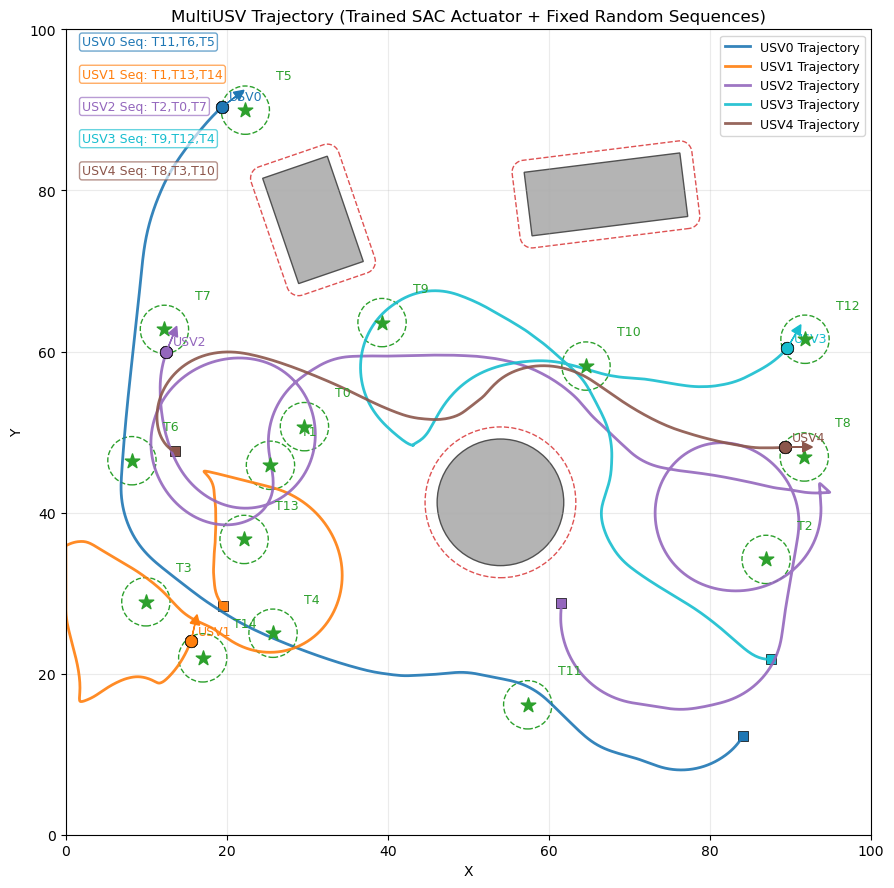

仿真步数: 651
终止原因: all_sequence_completed
已访问目标数: 15/15
USV碰撞对: []
障碍物碰撞标记: [False, False, False, False, False]
固定随机序列分配: [[11, 6, 5], [1, 13, 14], [2, 0, 7], [9, 12, 4], [8, 3, 10]]
各USV序列完成状态: [True, True, True, True, True]


In [7]:
import os
import torch
from sac_agent import SACActuatorAgent


# 使用 mpc_hrl_sac_output_310 下的 actuator 网络参数
MODEL_DIR = os.path.join(project_root, 'mpc_hrl_sac_output')
ACTOR_PATH = os.path.join(MODEL_DIR, 'actuator_actor.pth')
if not os.path.exists(ACTOR_PATH):
    ACTOR_PATH = os.path.join(MODEL_DIR, 'best_actuator_actor.pth')


def assign_target_sequences_once(env, rng):
    """仅初始化时随机分配一次目标序列，后续固定不变。"""
    perm = rng.permutation(env.num_targets).tolist()
    sequences = [[] for _ in range(env.num_usvs)]

    # 将随机打乱后的目标按轮转方式分给各 USV，确保每个目标仅归属一个 USV
    for k, tidx in enumerate(perm):
        sequences[k % env.num_usvs].append(int(tidx))

    return sequences


def build_goals_and_mask_from_sequences(env, sequences, seq_ptr):
    """根据固定序列和当前指针生成 goals 与 active_mask。"""
    goals = []
    active_mask = np.zeros(env.num_usvs, dtype=bool)

    for i in range(env.num_usvs):
        seq = sequences[i]
        ptr = seq_ptr[i]

        if ptr < len(seq):
            tidx = seq[ptr]
            t = env.targets[tidx]
            goals.append(np.array([t.x, t.y], dtype=np.float32))
            active_mask[i] = True
        else:
            usv = env.usvs[i]
            goals.append(np.array([usv.x, usv.y], dtype=np.float32))

    return goals, active_mask


def get_actuator_state_multi(single_usv_obs):
    """多USV观测中单艇 actuator 状态: o_usv(7)+o_detector+o_current(4)。"""
    return np.concatenate([
        single_usv_obs['o_usv'],
        single_usv_obs['o_detector'],
        single_usv_obs['o_current']
    ]).astype(np.float32)


def compute_actions_with_trained_actor(env, obs_multi, goals, actuator, active_mask):
    """使用训练好的 SAC actuator actor 产生动作。"""
    actions = np.zeros((env.num_usvs, 2), dtype=np.float32)
    for i in range(env.num_usvs):
        if not active_mask[i]:
            continue

        obs_i = obs_multi[f'usv_{i}']
        state_i = get_actuator_state_multi(obs_i)

        usv_pos_norm = obs_i['o_usv'][0:2]
        goal_abs = goals[i]
        goal_norm = np.array([goal_abs[0] / 100.0, goal_abs[1] / 100.0], dtype=np.float32)
        relative_goal = goal_norm - usv_pos_norm

        # evaluate=True: 确定性策略（用于可视化评估）
        action_i = actuator.select_action(state_i, relative_goal, evaluate=True)
        actions[i] = np.clip(action_i, -1.0, 1.0)

    return actions


# 创建仿真环境
env_traj = MultiUsvEnv(
    num_usvs=5,
    num_targets=15,
    num_obstacles=3,
    seed=2026,
    per_usv_max_steps=2000,
    current_type='generated'
)
obs_multi = env_traj.reset(seed=2026)

# 根据当前观测自动推断维度并构建 SAC actuator
state_dim = get_actuator_state_multi(obs_multi['usv_0']).shape[0]
goal_dim = 2
action_dim = 2
actuator = SACActuatorAgent(
    state_dim=state_dim,
    goal_dim=goal_dim,
    action_dim=action_dim,
    max_action=1.0
)

# 加载已训练 actor 参数
actor_state = torch.load(ACTOR_PATH, map_location='cpu')
actuator.actor.load_state_dict(actor_state)
actuator.actor.eval()

print(f'已加载 actuator 参数: {ACTOR_PATH}')
print(f'state_dim={state_dim}, goal_dim={goal_dim}, action_dim={action_dim}')

# 仅用于初始随机分配（固定种子便于复现）
rng = np.random.default_rng(2026)

# 一次性随机分配目标序列
sequences = assign_target_sequences_once(env_traj, rng)
seq_ptr = [0 for _ in range(env_traj.num_usvs)]

# 记录轨迹
max_steps = 2000
trajectories = [[] for _ in range(env_traj.num_usvs)]
for i in range(env_traj.num_usvs):
    trajectories[i].append(np.array([env_traj.usvs[i].x, env_traj.usvs[i].y], dtype=np.float32))

term_info = None

for step_i in range(max_steps):
    goals, active_mask = build_goals_and_mask_from_sequences(env_traj, sequences, seq_ptr)

    if not np.any(active_mask):
        term_info = {
            'termination_reason': 'all_sequence_completed',
            'target_status': env_traj.target_status.copy(),
            'usv_collision_pairs': [],
            'obstacle_collisions': [False] * env_traj.num_usvs
        }
        break

    actions = compute_actions_with_trained_actor(env_traj, obs_multi, goals, actuator, active_mask)

    obs_multi, done, crush, truncated, info = env_traj.step(
        actions,
        goals,
        usv_active_mask=active_mask
    )

    # 推进各 USV 的序列指针：当前目标被访问后转到下一个
    for i in range(env_traj.num_usvs):
        while seq_ptr[i] < len(sequences[i]):
            tidx = sequences[i][seq_ptr[i]]
            if info['target_status'][tidx] >= 0.5:
                seq_ptr[i] += 1
            else:
                break

    for i in range(env_traj.num_usvs):
        trajectories[i].append(np.array([env_traj.usvs[i].x, env_traj.usvs[i].y], dtype=np.float32))

    if done:
        term_info = info
        break

if term_info is None:
    term_info = info

# 绘图：环境 + 轨迹
fig, ax = plt.subplots(figsize=(9, 9))
plot_multi_usv_env(env_traj, ax=ax, title='MultiUSV Trajectory (Trained SAC Actuator + Fixed Random Sequences)')

cmap = ['#1F77B4', '#FF7F0E', '#9467BD', '#17BECF', '#8C564B']
for i in range(env_traj.num_usvs):
    traj = np.array(trajectories[i], dtype=np.float32)
    c = cmap[i % len(cmap)]
    ax.plot(traj[:, 0], traj[:, 1], color=c, linewidth=2.0, alpha=0.9, label=f'USV{i} Trajectory')
    ax.scatter(traj[0, 0], traj[0, 1], color=c, marker='s', s=55, edgecolors='black', linewidths=0.5)
    ax.scatter(traj[-1, 0], traj[-1, 1], color=c, marker='X', s=70, edgecolors='black', linewidths=0.5)

    seq_text = ','.join([f'T{t}' for t in sequences[i]]) if len(sequences[i]) > 0 else 'None'
    ax.text(2, 98 - i * 4, f'USV{i} Seq: {seq_text}', color=c, fontsize=9,
            bbox=dict(facecolor='white', alpha=0.65, edgecolor=c, boxstyle='round,pad=0.2'))

ax.legend(loc='upper right', fontsize=9)
plt.tight_layout()
plt.show()

# 统计输出
completed_per_usv = [seq_ptr[i] == len(sequences[i]) for i in range(env_traj.num_usvs)]
print(f"仿真步数: {len(trajectories[0]) - 1}")
print(f"终止原因: {term_info.get('termination_reason', 'running')}")
print(f"已访问目标数: {int(term_info['target_status'].sum())}/{env_traj.num_targets}")
print(f"USV碰撞对: {term_info.get('usv_collision_pairs', [])}")
print(f"障碍物碰撞标记: {term_info.get('obstacle_collisions', [])}")
print(f"固定随机序列分配: {sequences}")
print(f"各USV序列完成状态: {completed_per_usv}")